# Chapitre 11 - Exercices 11.1 à 11.6

Ce notebook traite les six premiers exercices du chapitre 11, centrés sur le transport
des flux et le lien entre bases de données et flux :

- **11.1** : sondage contre notification, qui coûte le moins cher ? (calcul et simulation) ;
- **11.2** : dimensionner les partitions d'un sujet, clés chaudes et changement du
  nombre de partitions (calcul et mini-lab) ;
- **11.3** : rétention, consommateur en panne et rattrapage (calcul) ;
- **11.4** : fréquence de validation des offsets et doublons (calcul et simulation) ;
- **11.5** : trouver l'anomalie d'un cache invalidé par double écriture (raisonnement
  et simulation) ;
- **11.6** : taille d'un sujet compacté (calcul et mini-lab).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 11.1 : sondage contre notification

**Énoncé.** 2 000 consommateurs veulent tous être informés des nouvelles lignes d'une
table `evenements`. Deux régimes de trafic : calme (0,1 événement par seconde) et chargé
(50 événements par seconde), arrivées de Poisson.

1. En sondage (polling) toutes les $T = 0{,}5$ s, combien de requêtes par seconde la base
   reçoit-elle ? Quelle fraction revient vide dans chaque régime ? Quel délai moyen
   avant qu'un événement soit vu ?
2. Avec un courtier qui pousse chaque événement à chaque consommateur (diffusion), combien
   de messages par seconde faut-il livrer dans chaque régime ?
3. Conclure : quand le sondage est-il plus économe que la notification ? Quel mécanisme
   simple rend le sondage acceptable quand le trafic est chargé ?
4. Vérifier les fractions vides et le délai par simulation.

**Rappels.** Interrogations vides avec probabilité $e^{-\lambda T}$, délai moyen $T/2$,
charge $n/T$ requêtes par seconde (cours 1, section 1, section *Transmitting Event
Streams*) ; diffusion à tous les consommateurs (cours 1, section 5, section *Multiple
consumers*).

**Solution.**

*1.* $n/T = 2\,000 / 0{,}5 = 4\,000$ requêtes par seconde, **quel que soit le trafic**.
Fraction vide : $e^{-0{,}1 \times 0{,}5} = e^{-0{,}05} \approx 95\,\%$ en régime calme,
$e^{-25} \approx 0$ en régime chargé. Délai moyen : $T/2 = 0{,}25$ s dans les deux cas.

*2.* Diffusion : $\lambda n$ livraisons par seconde, soit $0{,}1 \times 2\,000 = 200$ en
régime calme et $50 \times 2\,000 = 100\,000$ en régime chargé.

*3.* En régime calme, la notification fait 20 fois moins de travail (200 contre 4 000) :
la plupart des sondages sont inutiles. En régime chargé, c'est l'inverse : chaque sondage
rapporte en moyenne $\lambda T = 25$ événements d'un coup, donc 4 000 requêtes suffisent
là où la notification individuelle envoie 100 000 messages. Le seuil est
$\lambda n = n/T$, soit $\lambda T = 1$ : le sondage gagne quand il y a en moyenne plus
d'un événement par intervalle. Le remède côté notification est le **regroupement par
lots** (batching) : un consommateur de journal lit en une requête tous les messages
arrivés depuis son offset, ce qui combine l'absence de requêtes vides (il attend d'être
notifié, en « long polling ») et l'amortissement par lots.

**Vérification par simulation** : une heure d'événements de Poisson, un consommateur qui
sonde toutes les 0,5 s (les 2 000 consommateurs sont identiques).

In [2]:
T, n_cons, duree = 0.5, 2000, 3600
rows = []
for nom, lam in [("calme", 0.1), ("chargé", 50.0)]:
    t_ev = np.cumsum(rng.exponential(1 / lam, int(lam * duree * 1.2)))
    t_ev = t_ev[t_ev < duree]
    sondages = np.arange(T, duree + T, T)
    par_sondage = np.histogram(t_ev, bins=np.concatenate([[0], sondages]))[0]
    vu = np.ceil(t_ev / T) * T                               # prochain sondage après l'événement
    rows.append({"régime": nom, "requêtes/s (sondage)": n_cons / T, "vides (simulé)": (par_sondage == 0).mean(),
                 "vides (théorie)": math.exp(-lam * T), "délai moyen (s)": (vu - t_ev).mean(),
                 "livraisons/s (notification)": lam * n_cons, "événements par sondage": par_sondage.mean()})
pd.DataFrame(rows).set_index("régime")

,requêtes/s (sondage),vides (simulé),vides (théorie),délai moyen (s),livraisons/s (notification),événements par sondage
régime,,,,,,
calme,4000.0,0.957,9.512e-01,0.246,200.0,0.044
chargé,4000.0,0.000,1.389e-11,0.250,100000.0,25.071


Les fractions vides et le délai moyen de 0,25 s sont retrouvés. Le graphique situe le
seuil $\lambda T = 1$ pour 2 000 consommateurs.

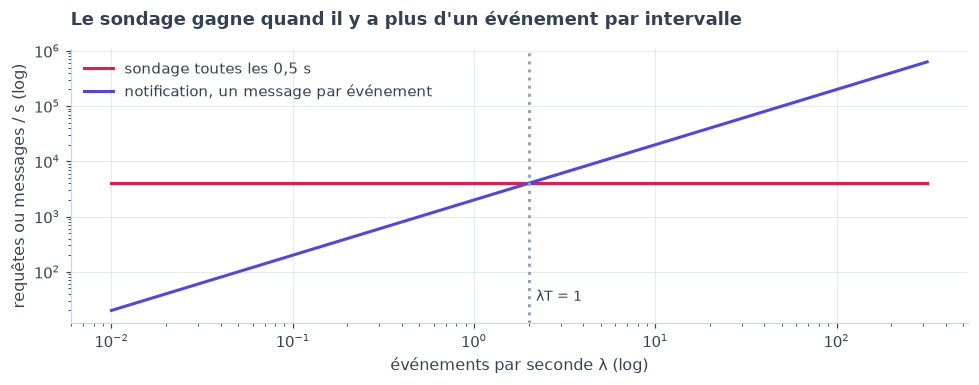

In [3]:
lams = np.logspace(-2, 2.5, 200)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(lams, np.full_like(lams, n_cons / T), color=ROSE, label="sondage toutes les 0,5 s")
ax.plot(lams, lams * n_cons, color=INDIGO, label="notification, un message par événement")
ax.axvline(1 / T, color=GRAY, ls=":")
ax.text(1 / T * 1.1, 30, "λT = 1", color=SLATE, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("événements par seconde λ (log)"); ax.set_ylabel("requêtes ou messages / s (log)")
ax.set_title("Le sondage gagne quand il y a plus d'un événement par intervalle")
ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Le sondage coûte $n/T$ quel que soit le trafic, la notification $\lambda n$ ;
> le seuil est $\lambda T = 1$. Les journaux combinent le meilleur des deux : notification
> (pas de requête vide) et lecture par lots (coût amorti).

## Exercice 11.2 : dimensionner les partitions d'un sujet

**Énoncé.** Un sujet reçoit en pointe 120 Mo/s de messages de 1 Ko, avec l'identifiant
de l'utilisateur comme clé. Une partition supporte au plus 10 Mo/s en écriture (limite
observée du disque et de la réplication) ; un consommateur traite 6 000 messages par
seconde.

1. Combien de partitions au minimum pour l'écriture ? Pour la consommation ? Combien de
   consommateurs au plus seront utiles dans un groupe ?
2. La popularité des utilisateurs suit une loi de Zipf ($s = 1{,}1$, 1 million
   d'utilisateurs). Avec 24 partitions et le partitionneur de Kafka (`st.kafka_partition`),
   quelle est la charge de la partition la plus chargée, rapportée à la moyenne ? Que
   faut-il en conclure pour le dimensionnement ?
3. Six mois plus tard, on passe de 24 à 32 partitions. Quelle fraction des clés change de
   partition ? Quelle garantie est perdue pendant la transition ?

**Rappels.** Une partition est lue par un seul consommateur du groupe ; l'ordre n'est
garanti que dans une partition ; la partition d'une clé est
$\text{murmur2}(\text{clé}) \bmod P$ (cours 2, sections 1 et 2, sections *Using logs for
message storage* et *Logs compared to traditional messaging* ; clés chaudes : chapitre
6).

**Solution.**

*1.* Écriture : $120 / 10 = 12$ partitions au minimum. Consommation : 120 Mo/s de
messages de 1 Ko font environ 123 000 messages par seconde (avec 1 Ko = 1 024 octets et
1 Mo = 1 048 576 octets, soit 122 880), donc $\lceil 122\,880 / 6\,000 \rceil = 21$
consommateurs, donc **au moins 21 partitions** (un consommateur par partition au plus).
Le nombre de consommateurs utiles est plafonné par le nombre de partitions.

*2.* Les clés ne sont pas également actives : une partition reçoit toutes les clés
chaudes que le hachage lui attribue. On le mesure ci-dessous. Il faut dimensionner pour
la **partition la plus chargée**, pas pour la moyenne : soit prévoir davantage de
partitions et de marge, soit traiter à part les clés les plus chaudes (par exemple en leur
ajoutant un suffixe aléatoire, au prix de l'ordre entre leurs messages).

*3.* Avec un partitionnement par $\bmod P$, une clé ne reste en place que si
$h \bmod 24 = h \bmod 32$. Ces deux restes ne dépendent que de $r = h \bmod 96$
(96 est le PPCM de 24 et 32) ; en passant en revue les 96 valeurs de $r$, l'égalité n'a
lieu que pour $r < 24$. Un quart des clés reste en place, **trois quarts changent de
partition**. Pendant la transition, les anciens messages d'une clé sont dans l'ancienne
partition et les nouveaux dans une autre : **l'ordre par clé n'est plus garanti** (un
consommateur peut lire un message récent avant un ancien).

partitions minimales : écriture 12, consommation 21
partition la plus chargée : 3.50 × la moyenne ; la clé la plus chaude seule pèse 12.4% du trafic (2.97 × une partition moyenne)
clés qui changent de partition (24 -> 32) : 75.0%


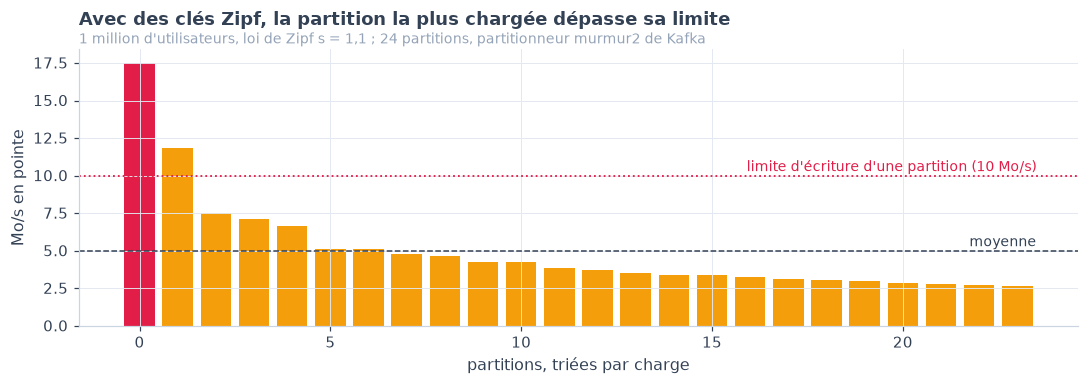

In [4]:
n_users, P = 1_000_000, 24
poids = 1 / np.arange(1, n_users + 1) ** 1.1
poids /= poids.sum()
cles = [f"user-{i}" for i in range(n_users)]
part24 = np.array([st.kafka_partition(k, 24) for k in cles])
part32 = np.array([st.kafka_partition(k, 32) for k in cles])
charge = np.bincount(part24, weights=poids, minlength=24)
print(f"partitions minimales : écriture {math.ceil(120 / 10)}, consommation {math.ceil(120 * 1024 / 6000)}")
print(f"partition la plus chargée : {charge.max() / charge.mean():.2f} × la moyenne ; "
      f"la clé la plus chaude seule pèse {poids[0]:.1%} du trafic ({poids[0] * 24:.2f} × une partition moyenne)")
print(f"clés qui changent de partition (24 -> 32) : {(part24 != part32).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ordre = np.argsort(-charge)
ax.bar(range(24), charge[ordre] * 120, color=[ROSE if i == 0 else AMBER for i in range(24)])
ax.axhline(120 / 24, color=SLATE, ls="--", lw=1)
ax.axhline(10, color=ROSE, ls=":", lw=1.2)
ax.text(23.5, 10.3, "limite d'écriture d'une partition (10 Mo/s)", ha="right", color=ROSE, fontsize=9)
ax.text(23.5, 120 / 24 + 0.3, "moyenne", ha="right", color=SLATE, fontsize=9)
ax.set_xlabel("partitions, triées par charge"); ax.set_ylabel("Mo/s en pointe")
ax.set_title("Avec des clés Zipf, la partition la plus chargée dépasse sa limite")
subtitle(ax, "1 million d'utilisateurs, loi de Zipf s = 1,1 ; 24 partitions, partitionneur murmur2 de Kafka")
plt.tight_layout(); plt.show()

La partition qui hérite de la clé la plus chaude reçoit 3,5 fois la charge moyenne et
dépasse largement la limite de 10 Mo/s (une deuxième partition la dépasse aussi), alors que la moyenne (5 Mo/s) laisse une marge
confortable. Ajouter des partitions ne résout rien pour cette clé : une clé ne se
partage pas. Et changer le nombre de partitions déplace les trois quarts des clés,
comme prévu : c'est pourquoi on surdimensionne le nombre de partitions dès
la création d'un sujet.

> **À retenir.** Dimensionner un sujet : $\max(\text{débit} / \text{débit par partition},
> \text{messages/s} / \text{capacité d'un consommateur})$ partitions, plus une marge pour la
> partition la plus chargée ; les clés chaudes ne se divisent pas, et changer le nombre
> de partitions casse l'ordre par clé.

## Exercice 11.3 : rétention, consommateur en panne et rattrapage

**Énoncé.** Un cluster de 6 courtiers a chacun 8 To de disque utile pour le journal ; le
facteur de réplication est 3. Le trafic d'écriture vaut 40 Mo/s en moyenne, avec chaque
jour un pic de 2 heures à 120 Mo/s (inclus dans la moyenne).

1. Quelle rétention maximale (en jours) le cluster permet-il, en gardant 20 % de disque
   libre ?
2. Un consommateur d'analyse tombe en panne vendredi à 18 h et n'est relancé que lundi à
   6 h. Perd-il des messages avec une rétention de 3 jours ? de 2 jours ?
3. Relancé, il traite 70 Mo/s. Combien de temps lui faut-il pour rattraper son retard,
   en supposant le trafic au niveau moyen (pics compris dans la moyenne) ?
4. Vérifier le rattrapage par une simulation heure par heure, avec les pics quotidiens.

**Rappels.** Le journal est un tampon circulaire de capacité « espace / débit » ; un
consommateur perd des messages si son retard dépasse la rétention ; le retard se résorbe
à la vitesse « capacité - débit » (cours 2, section 4, sections *Disk space usage* et
*When consumers cannot keep up with producers*).

**Solution.**

*1.* Espace utile : $6 \times 8 \times 0{,}8 = 38{,}4$ To, mais chaque message est stocké
3 fois : 12,8 To de données distinctes. À 40 Mo/s, on écrit $40 \times 86\,400 \approx
3{,}46$ To par jour : la rétention maximale est $12{,}8 / 3{,}46 \approx 3{,}7$ jours.

*2.* La panne dure 60 heures (2,5 jours). Avec 3 jours de rétention, le premier message
non lu (vendredi 18 h) est encore là lundi 6 h : pas de perte, de justesse (12 heures de
marge). Avec 2 jours, lundi 6 h, le journal ne remonte plus qu'à samedi 6 h : les
messages de vendredi 18 h à samedi 6 h (12 heures de trafic) ont été supprimés avant
d'être lus : perte.

*3.* Retard au redémarrage : 60 h de trafic moyen, $40 \times 60 \times 3\,600 = 8{,}64$ To.
Marge de rattrapage : $70 - 40 = 30$ Mo/s, donc $8{,}64 \cdot 10^6 / 30 = 288\,000$ s
$= 80$ heures, plus de trois jours. Pendant ce temps, le consommateur lit des messages de
plus en plus récents, mais son retard reste supérieur à 2,5 jours au début : avec une
rétention de 3 jours, il ne doit surtout pas ralentir.

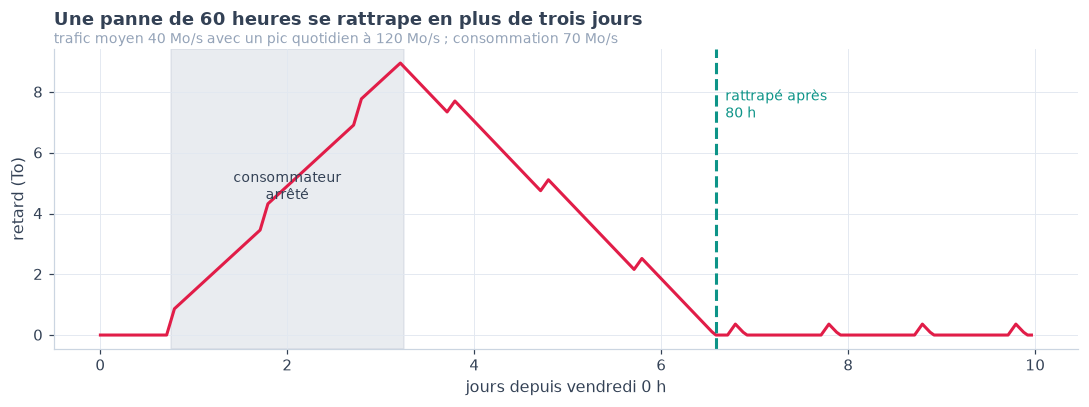

espace distinct : 12.8 To ; rétention max : 3.70 jours
retard max : 8.95 To (62 h de trafic moyen) ; rattrapage : 80 h


In [5]:
heures = np.arange(0, 24 * 10)
debit = np.where((heures % 24 >= 18) & (heures % 24 < 20), 120.0, (40 * 24 - 2 * 120) / 22)   # Mo/s, moyenne 40
panne = (heures >= 18) & (heures < 18 + 60)
retard, r = np.zeros(heures.size), 0.0
for h in heures:
    r = max(0.0, r + debit[h] * 3600 - (0 if panne[h] else 70 * 3600))
    retard[h] = r
retard_h = retard / (40 * 3600)                               # en heures de trafic moyen
fin = heures[(heures > 78) & (retard == 0)][0]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(heures / 24, retard / 1e6, color=ROSE)
ax.axvspan(18 / 24, 78 / 24, color=GRAY, alpha=0.2)
ax.text(48 / 24, retard.max() / 1e6 * 0.5, "consommateur\narrêté", ha="center", color=SLATE, fontsize=9)
ax.axvline(fin / 24, color=TEAL, ls="--")
ax.text(fin / 24 + 0.1, retard.max() / 1e6 * 0.8, f"rattrapé après\n{fin - 78} h", color=TEAL, fontsize=9)
ax.set_xlabel("jours depuis vendredi 0 h"); ax.set_ylabel("retard (To)")
ax.set_title("Une panne de 60 heures se rattrape en plus de trois jours")
subtitle(ax, "trafic moyen 40 Mo/s avec un pic quotidien à 120 Mo/s ; consommation 70 Mo/s")
plt.tight_layout(); plt.show()
print(f"espace distinct : {6 * 8 * 0.8 / 3:.1f} To ; rétention max : {6 * 8 * 0.8 / 3 / (40 * 86400 / 1e6):.2f} jours")
print(f"retard max : {retard.max() / 1e6:.2f} To ({retard_h.max():.0f} h de trafic moyen) ; rattrapage : {fin - 78} h")

La simulation donne un retard d'environ 9 To (les pics quotidiens tombés pendant la panne
l'alourdissent un peu par rapport aux 8,6 To du calcul moyen) et un rattrapage d'environ
80 heures. Leçon pratique : surveiller le retard des
consommateurs et dimensionner leur capacité de rattrapage, pas seulement leur capacité
en régime permanent.

> **À retenir.** Rétention = espace distinct / débit ; une panne de durée $D$ crée un retard
> $D$ qui se résorbe en $D \times \text{débit} / (\text{capacité} - \text{débit})$.

## Exercice 11.4 : fréquence de validation des offsets et doublons

**Énoncé.** Un consommateur traite 5 000 messages par seconde et valide son offset toutes
les $t$ secondes. Il tombe en panne en moyenne 3 fois par jour (redéploiements compris).
Chaque validation coûte une écriture répliquée dans le courtier.

1. Exprimer le nombre moyen de messages retraités par jour en fonction de $t$.
2. Quelle valeur de $t$ garantit moins de 10 doublons pour un million de messages ?
   Combien de validations par jour cela représente-t-il ?
3. Vérifier la formule avec `st.simulate_offset_commits`, à échelle réduite.
4. Le traitement envoie un courriel par message. Pourquoi aucune valeur de $t$ ne
   suffit-elle ?

**Rappels.** Après une panne, on reprend au dernier offset validé ; en moyenne une demi-
période de validation est retraitée (cours 2, section 3, section *Consumer offsets*) ;
effets externes et « exactement une fois » : cours 7, sections 6 et 7.

**Solution.**

*1.* Une panne tombe en moyenne au milieu d'une période de validation : elle fait
retraiter $r\,t/2$ messages. Par jour : $D(t) = 3 \times 5\,000 \times t / 2 = 7\,500\,t$.

*2.* Messages par jour : $5\,000 \times 86\,400 = 4{,}32 \cdot 10^8$. Il faut
$7\,500\,t < 10^{-5} \times 4{,}32 \cdot 10^8 = 4\,320$, soit $t < 0{,}576$ s : valider
toutes les 0,5 s, soit 172 800 validations par jour (2 par seconde), une charge minime
pour le courtier. Valider à chaque message (5 000 par seconde) serait bien plus coûteux
pour un gain marginal.

*3.* À échelle réduite : 200 000 messages, panne avec probabilité $p$ après chaque
message, validation tous les $c$ messages ; doublons attendus : $n\,p\,(c-1)/2$.

In [6]:
rows = []
for c in [10, 50, 200, 1000]:
    sims = [st.simulate_offset_commits(200_000, c, 5e-5, seed=s) for s in range(8)]
    rows.append({"c": c, "doublons simulés": np.mean([x["duplicates"] for x in sims]),
                 "théorie n·p·(c-1)/2": 200_000 * 5e-5 * (c - 1) / 2})
pd.DataFrame(rows).set_index("c").round(1)

,doublons simulés,théorie n·p·(c-1)/2
c,,
10,43.2,45.0
50,232.0,245.0
200,1046.6,995.0
1000,4321.1,4995.0


La simulation suit la formule (aux fluctuations du nombre de pannes près).

*4.* Un courriel est un **effet externe** : s'il a été envoyé avant la panne mais après la
dernière validation, le rejeu le renvoie. Réduire $t$ réduit la probabilité, jamais à
zéro. Il faut rendre l'effet idempotent (noter dans une base, dans la même transaction que
l'envoi demandé, l'identifiant du message traité, et ne pas renvoyer un courriel déjà
envoyé), ou accepter de rares doublons.

> **À retenir.** Doublons par panne ≈ débit × période de validation / 2 : valider souvent
> coûte peu et réduit les doublons, mais seuls l'idempotence ou un commit atomique les
> éliminent pour les effets externes.

## Exercice 11.5 : l'anomalie du cache invalidé par double écriture

**Énoncé.** Un service lit les profils via un cache (stratégie « cache-aside ») : en cas
d'absence dans le cache, il lit la base puis écrit la valeur lue dans le cache. Pour une
mise à jour, il écrit dans la base puis **supprime** l'entrée du cache. L'équipe pense
que supprimer (plutôt qu'écrire) l'entrée suffit à éviter la course de la double
écriture.

1. Trouver un entrelacement d'un lecteur et d'un écrivain qui laisse dans le cache une
   valeur périmée **pour une durée indéfinie**. Le représenter.
2. Estimer par simulation la fréquence de l'anomalie en fonction de la latence de la
   base.
3. Proposer une correction fondée sur la capture des changements.

**Rappels.** Double écriture et ses deux défauts ; CDC et ordre de validation (cours 3,
sections 2 et 3, sections *Keeping Systems in Sync* et *Change Data Capture*).

**Solution.**

*1.* Le lecteur constate une absence dans le cache et lit la base : il obtient l'ancienne
valeur v1. Avant qu'il n'écrive dans le cache, l'écrivain met la base à v2 et supprime
l'entrée du cache (qui est déjà absente). Le lecteur écrit alors v1 dans le cache. La
base contient v2, le cache v1, et rien ne corrigera le cache avant la prochaine mise à
jour ou l'expiration de l'entrée.

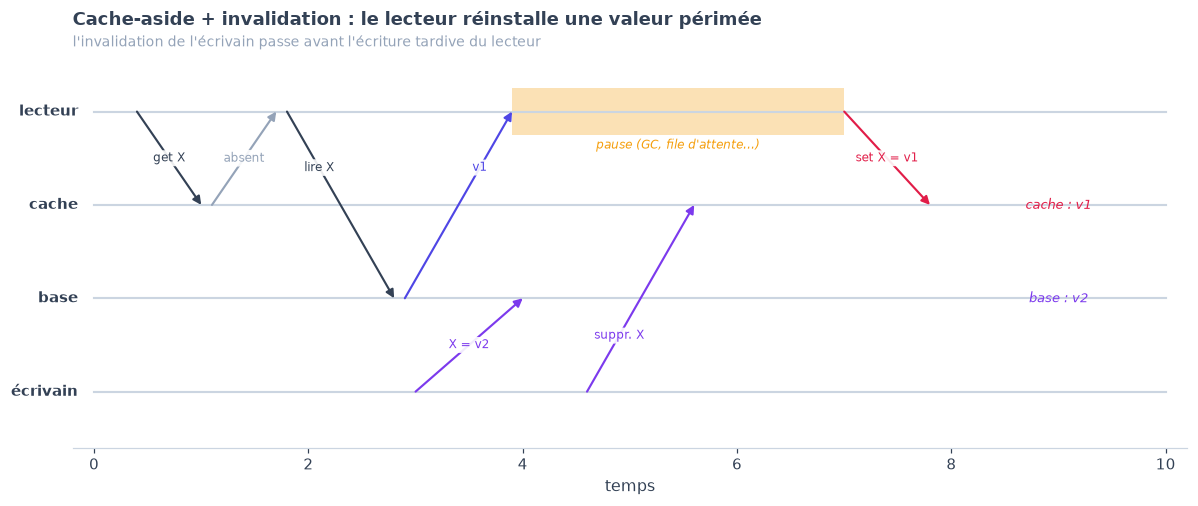

In [7]:
stt = SpaceTime(["lecteur", "cache", "base", "écrivain"], t_max=10, width=11,
                title="Cache-aside + invalidation : le lecteur réinstalle une valeur périmée",
                subtitle="l'invalidation de l'écrivain passe avant l'écriture tardive du lecteur")
stt.msg("lecteur", 0.4, "cache", 1.0, "get X", color=SLATE)
stt.msg("cache", 1.1, "lecteur", 1.7, "absent", color=GRAY)
stt.msg("lecteur", 1.8, "base", 2.8, "lire X", color=SLATE, label_pos=0.3)
stt.msg("base", 2.9, "lecteur", 3.9, "v1", color=INDIGO, label_pos=0.7)
stt.span("lecteur", 3.9, 7.0, "pause (GC, file d'attente...)", color=AMBER, alpha=0.3)
stt.msg("écrivain", 3.0, "base", 4.0, "X = v2", color=VIOLET)
stt.msg("écrivain", 4.6, "cache", 5.6, "suppr. X", color=VIOLET, label_pos=0.3)
stt.msg("lecteur", 7.0, "cache", 7.8, "set X = v1", color=ROSE)
stt.note(9.0, "cache", "cache : v1", color=ROSE, dy=0.0)
stt.note(9.0, "base", "base : v2", color=VIOLET, dy=0.0)
stt.show()

*2.* Simulation : lectures et écritures d'une même clé arrivent selon des processus de
Poisson (une écriture pour neuf lectures) ; chaque accès à la base prend un temps
exponentiel de moyenne $m$ (en unités de l'intervalle moyen entre requêtes), le cache est
instantané. On mesure la **fraction du temps** pendant laquelle le cache contient une
valeur différente de celle de la base, dans le pire cas où chaque lecture manque le
cache, et surtout le nombre d'**installations durables** : un lecteur installe une
version plus ancienne que la base **après** que l'invalidation de la nouvelle version a
eu lieu, si bien que rien ne la corrigera avant la prochaine écriture. La variante
corrigée (question 3) est simulée en même temps.

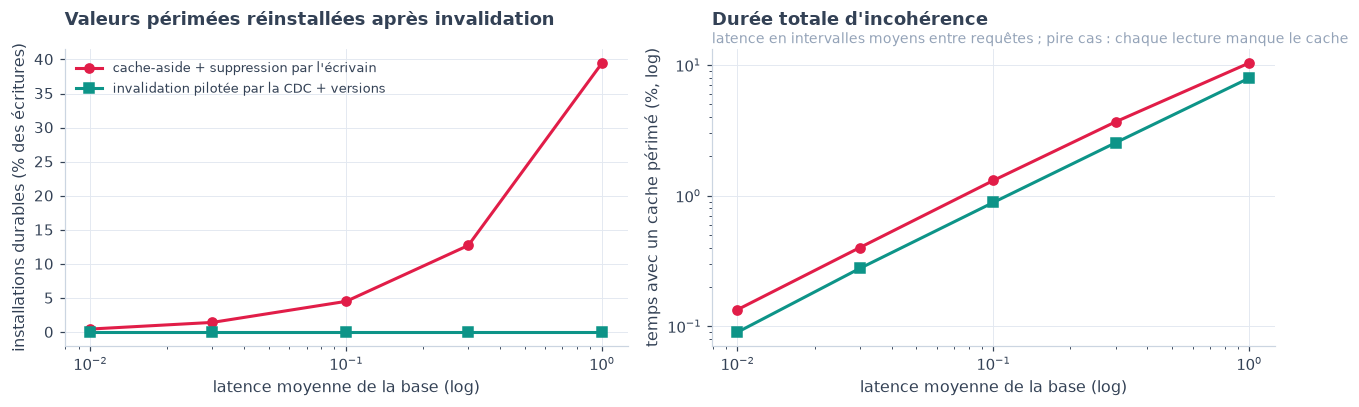

,naïf : installations durables (%),CDC : installations durables (%),naïf : temps périmé (%),CDC : temps périmé (%)
latence,,,,
0.01,0.462,0.0,0.134,0.090
0.03,1.436,0.0,0.400,0.277
0.10,4.525,0.0,1.308,0.888
0.30,12.725,0.0,3.675,2.542
1.00,39.486,0.0,10.394,7.964


In [8]:
def simuler_cache(n_ops, m_base, seed, cdc=False):
    r = np.random.default_rng(seed)
    t, version, evts = 0.0, 0, []                  # (instant, n° d'opération, type, version)
    for i in range(n_ops):
        t += r.exponential(1.0)
        if r.random() < 0.1:                       # écriture : base, puis invalidation
            version += 1
            t_db = t + r.exponential(m_base)
            evts.append((t_db, i, "db_write", version))
            # naïf : l'écrivain supprime l'entrée juste après ; CDC : le consommateur du journal
            # l'invalide un peu plus tard, avec la version
            evts.append((t_db + r.exponential(m_base), i, "invalidate", version))
        else:                                      # lecture qui manque le cache : base, puis cache
            t_lu = t + r.exponential(m_base)
            evts.append((t_lu, i, "db_read", None))
            evts.append((t_lu + r.exponential(m_base), i, "cache_set", None))
    evts.sort()
    db, cache, plancher, lus = 0, None, 0, {}
    perime, t_prec, durables, invalide = 0.0, 0.0, 0, 0
    for tt, i, kind, v in evts:
        if cache is not None and cache != db:
            perime += tt - t_prec
        t_prec = tt
        if kind == "db_write":
            db = v
        elif kind == "db_read":
            lus[i] = db
        elif kind == "cache_set":
            if not cdc or lus[i] >= plancher:      # CDC : jamais une version plus ancienne que la dernière vue
                cache = lus[i]
                if cache < db and invalide >= db:  # périmée et plus aucune invalidation à venir
                    durables += 1
        elif kind == "invalidate":
            invalide = max(invalide, v)
            if cdc:
                plancher = max(plancher, v)
                if cache is not None and cache < v:
                    cache = None
            else:
                cache = None
    return perime / t_prec, durables / version

ms = [0.01, 0.03, 0.1, 0.3, 1.0]
naif = np.array([np.mean([simuler_cache(20_000, m, s) for s in range(5)], axis=0) for m in ms])
corr = np.array([np.mean([simuler_cache(20_000, m, s, cdc=True) for s in range(5)], axis=0) for m in ms])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax.plot(ms, naif[:, 1] * 100, "o-", color=ROSE, label="cache-aside + suppression par l'écrivain")
ax.plot(ms, corr[:, 1] * 100, "s-", color=TEAL, label="invalidation pilotée par la CDC + versions")
ax.set_xscale("log")
ax.set_xlabel("latence moyenne de la base (log)"); ax.set_ylabel("installations durables (% des écritures)")
ax.set_title("Valeurs périmées réinstallées après invalidation")
ax.legend(fontsize=8.5)
ax2.plot(ms, naif[:, 0] * 100, "o-", color=ROSE); ax2.plot(ms, corr[:, 0] * 100, "s-", color=TEAL)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("latence moyenne de la base (log)"); ax2.set_ylabel("temps avec un cache périmé (%, log)")
ax2.set_title("Durée totale d'incohérence")
subtitle(ax2, "latence en intervalles moyens entre requêtes ; pire cas : chaque lecture manque le cache")
plt.tight_layout(); plt.show()
pd.DataFrame({"latence": ms, "naïf : installations durables (%)": naif[:, 1] * 100,
              "CDC : installations durables (%)": corr[:, 1] * 100, "naïf : temps périmé (%)": naif[:, 0] * 100,
              "CDC : temps périmé (%)": corr[:, 0] * 100}).set_index("latence").round(3)

Plus la base est lente par rapport au rythme des requêtes, plus la fenêtre de la course
est large : avec une base lente, une part notable des écritures est suivie d'une
réinstallation durable d'une valeur périmée, qui n'est corrigée qu'à la prochaine
écriture. La variante corrigée n'en fait **aucune** ; elle reste périmée un court instant
après chaque écriture, le temps que l'invalidation asynchrone arrive, ce qui explique
que la durée totale d'incohérence ne baisse que modérément dans ce modèle où chaque
lecture manque le cache.

*3.* Correction : l'invalidation n'est plus faite par l'écrivain mais par un consommateur
du **journal des changements** de la base, dans l'ordre de validation ; et chaque valeur
mise en cache porte sa **version** (le numéro de séquence du journal, ou une colonne de
version), le cache refusant d'installer une version plus ancienne que celle qu'il a vue
passer dans le journal (une écriture conditionnelle, du type « compare-and-set »). Le
lecteur tardif ne peut plus réinstaller v1 après l'invalidation de v2. Une durée de vie
(TTL) sur les entrées borne de toute façon la durée de l'incohérence.

> **À retenir.** Supprimer l'entrée au lieu de l'écrire ne supprime pas la course : un
> lecteur lent peut réinstaller une valeur périmée. Ordonner les invalidations selon le
> journal de la base et versionner les entrées la ferme.

## Exercice 11.6 : taille d'un sujet compacté

**Énoncé.** Un sujet de CDC compacté porte l'état de 10 millions de clés (valeurs de
500 octets en moyenne, clé et en-têtes compris). Il reçoit 2 000 mises à jour par seconde,
réparties uniformément sur les clés. Le nettoyeur compacte une partition dès que la part
« sale » (enregistrements écrits depuis la dernière compaction) dépasse 50 % de la
partition (comme `min.cleanable.dirty.ratio = 0.5` dans Kafka).

1. Quelle est la taille de l'état « propre » ? Quelle taille maximale le sujet atteint-il
   avant compaction ? Combien de temps s'écoule entre deux compactions ?
2. Sans compaction, quelle taille au bout de 30 jours ?
3. Simuler à échelle réduite avec `PartitionedLog` (10 000 clés, compaction déclenchée
   au seuil de 50 %) et tracer la taille du journal.
4. On supprime 20 % des clés par des pierres tombales. Que devient la taille ? Pourquoi
   Kafka garde-t-il les pierres tombales un certain temps avant de les effacer ?

**Rappels.** Compaction : dernière valeur par clé, pierres tombales, segment actif non
compacté (cours 3, section 5, section *Log compaction*).

**Solution.**

*1.* État propre : $10^7 \times 500$ o = 5 Go. La compaction se déclenche quand la part
sale atteint 50 %, c'est-à-dire quand on a écrit autant que l'état propre : le sujet
oscille entre 5 Go et environ 10 Go. Écrire 5 Go à $2\,000 \times 500$ o/s = 1 Mo/s prend
5 000 s, environ 1 h 25 entre deux compactions.

*2.* Sans compaction : $1$ Mo/s $\times 30 \times 86\,400$ s $\approx 2{,}6$ To, plus les
5 Go initiaux : 500 fois l'état.

*3.* Simulation : on déclenche `compact` quand les enregistrements écrits depuis la
dernière compaction dépassent 50 % de la taille du journal.

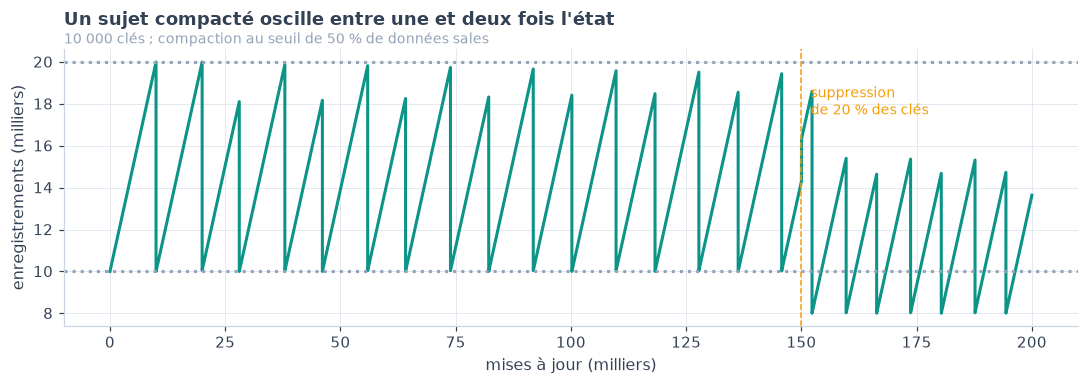

taille min / max après la phase initiale : 10000 / 19888 ; après suppression : 8006 / 15368


In [9]:
n_cles, n_maj = 10_000, 200_000
log = st.PartitionedLog(1, segment_size=1000)
for k in range(n_cles):
    log.append(k, 0, partition=0)
log.compact(0)
taille, sale = [], 0
for i in range(n_maj):
    if i == 150_000:
        for k in range(int(0.8 * n_cles), n_cles):           # suppression de 20 % des clés
            log.append(k, None, partition=0)
            sale += 1
    k = int(rng.integers(0, n_cles if i < 150_000 else int(0.8 * n_cles)))
    log.append(k, i, partition=0)
    sale += 1
    if sale > 0.5 * log.size(0):
        log.compact(0)
        sale = log.size(0) - sum(len(sg) for sg in log.segments[0][:-1])   # le segment actif reste « sale »
    taille.append(log.size(0))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(np.arange(n_maj) / 1000, np.array(taille) / 1000, color=TEAL)
ax.axhline(n_cles / 1000, color=GRAY, ls=":")
ax.axhline(2 * n_cles / 1000, color=GRAY, ls=":")
ax.axvline(150, color=AMBER, ls="--", lw=1)
ax.text(152, 17.5, "suppression\nde 20 % des clés", color=AMBER, fontsize=9)
ax.set_xlabel("mises à jour (milliers)"); ax.set_ylabel("enregistrements (milliers)")
ax.set_title("Un sujet compacté oscille entre une et deux fois l'état")
subtitle(ax, "10 000 clés ; compaction au seuil de 50 % de données sales")
plt.tight_layout(); plt.show()
print(f"taille min / max après la phase initiale : {min(taille[20_000:150_000])} / {max(taille[20_000:150_000])} "
      f"; après suppression : {min(taille[160_000:])} / {max(taille[160_000:])}")

Le journal oscille entre environ 10 000 et 20 000 enregistrements (l'état et deux fois
l'état), en dents de scie ; après la suppression de 20 % des clés, l'oscillation descend
entre 8 000 et 16 000 environ. L'**amplification d'espace** d'un sujet compacté vaut donc
au plus $1/(1 - \text{seuil})$ = 2 avec ce réglage ; un seuil plus bas économise de
l'espace au prix de compactions plus fréquentes (amplification d'écriture, chapitre
3).

*4.* Après compaction, les clés supprimées disparaissent : l'état propre n'en contient
plus que 8 000. Kafka garde pourtant chaque pierre tombale un certain temps
(`delete.retention.ms`) : un consommateur qui relit le sujet depuis le début, ou qui est
en retard, doit **voir** la suppression pour l'appliquer à sa copie ; si la pierre
tombale était effacée trop tôt, il garderait l'ancienne valeur pour toujours.

> **À retenir.** Un sujet compacté occupe entre « état » et « état / (1 - seuil) » ; sans
> compaction, la taille croît avec l'historique. Les pierres tombales doivent survivre
> assez longtemps pour que tous les consommateurs voient les suppressions.